# eccNET: Attention Maps, Scanpath & Pooling-Blur

Ein Search Image und ein Target Image laufen durch eccNET (Abmessungen wie bei Waldo/NaturalDesign):

- **Search Image** → resized auf 736×896 (H×W), intern mit 800 px gepolstert. Das Modell sieht ein **1600×1600**-Fenster um die aktuelle Fixation.
- **Target Image** → resized auf 32×32.
- **GT-Maske** (optional, Ziel = weiß): Damit stoppt die Suche, sobald das Ziel gefunden ist. Ohne Maske läuft der Scanpath genau `num_fix` Fixationen lang.

Ausgaben:
1. Attention Maps der 3 Feature-Layer (Block 3/4/5) + Gesamtmap bei der ersten Fixation (Bildmitte), als Overlay.
2. Scanpath als Overlay.
3. Blur der Pooling-Layers: Convs übersprungen (= Identität), das RGB-Bild läuft nur durch die 5 Pooling-Layers. Gezeigt wird das Bild kumulativ nach Pool 3, 4 und 5.

## Setup

In [8]:
import sys, os, pathlib

_cwd = pathlib.Path.cwd().resolve()
repo_root = next(p for p in [_cwd] + list(_cwd.parents) if (p / "vs_model").is_dir())
sys.path.insert(0, str(repo_root))

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from vs_model import VisualSearchModel
from vs_model.ecc_net import pool_layer, eccParamDefault

for dev in tf.config.list_physical_devices('GPU'):
    tf.config.experimental.set_memory_growth(dev, True)

## Parameter

In [14]:
data_dir = repo_root / "notebooks" / "stimuli"
search_path = str(data_dir / "lung.png" )   # eigenes Bild hier eintragen
target_path = str(data_dir / "target.png")
gt_path = str(data_dir / "mask.png")                                          # None -> keine Zielerkennung, Suche läuft num_fix Fixationen
num_fix = 10

out_dir = repo_root / "notebooks" / "out" / "attention_vis"
out_dir.mkdir(parents=True, exist_ok=True)

if gt_path is None:
    gt_path = str(out_dir / "_empty_gt.png")
    cv2.imwrite(gt_path, np.zeros((736, 896), np.uint8))

for p in (search_path, target_path, gt_path):
    assert os.path.isfile(p), f"Datei nicht gefunden: {p}"

# exp_info wie Waldo/NaturalDesign (vs_saccade_exp/data_utils.get_exp_info), nur NumFix anpassbar
exp_info = {
    'eye_res': 736,
    'stim_shape': (736, 896, 3),
    'tar_shape': (32, 32, 3),
    'ior_size': 64,
    'NumStimuli': 1,
    'NumFix': num_fix,
    'gt_mask': None,
    'fix': None,
    'bg_value': 0,
    'rev_img_flag': 0,
    'deg2px': 30,
    'weight_pattern': 'l',
    'dog_size': [[3, 0], [5, 1]],
    's_ratio': None,
}
corner_bias = 16*4*1
E = exp_info['eye_res'] + corner_bias    # 800: Padding & halbe Fensterbreite
H, W = exp_info['stim_shape'][:2]

model_desc = {
    'eccParam': dict(eccParamDefault),
    'ecc_depth': 5,
    'out_layer': [1, 1, 1],
    'comp_layer': 'diff',
    'vgg_model_path': str(repo_root / "pretrained_model" / "vgg16_imagenet_filters.h5"),
    'model_subname': "",
}

## Modell laden & Suche ausführen

In [15]:
vsm = VisualSearchModel(model_desc)
vsm.load_exp_info(exp_info, corner_bias=corner_bias)
saccade, attn_maps, vis_crops, layer_maps = vsm.start_search(search_path, target_path, gt_path, debug_flag=True)

search_img = cv2.cvtColor(cv2.resize(cv2.imread(search_path), (W, H), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
print("Fixationen (row, col):\n", saccade)

1/1 [==============================] - 0s 165ms/step


2026-10-08 16:23:14.987020: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.
2026-10-08 16:23:15.286269: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 0s 217ms/step
Fixationen (row, col):
 [[368 448]
 [384 336]
 [304 272]
 [208 192]]


## Attention Maps bei der ersten Fixation

Die Maps liegen im 1600×1600-Fenster um die Fixation. Für das Overlay wird auf den Stimulusbereich zugeschnitten.

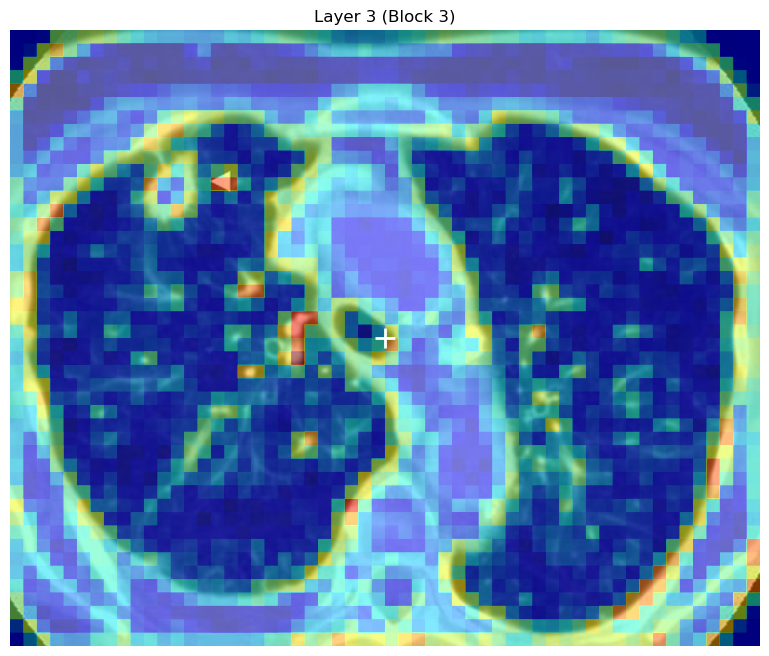

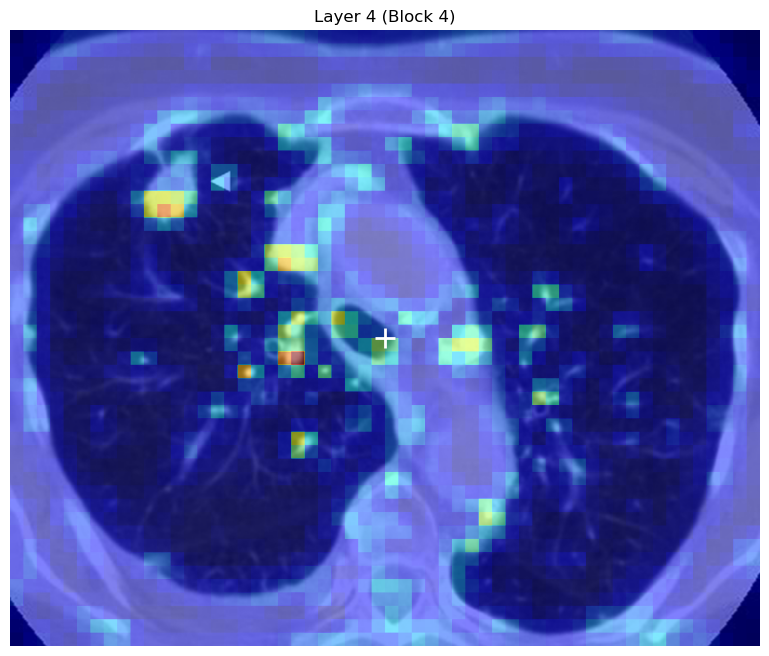

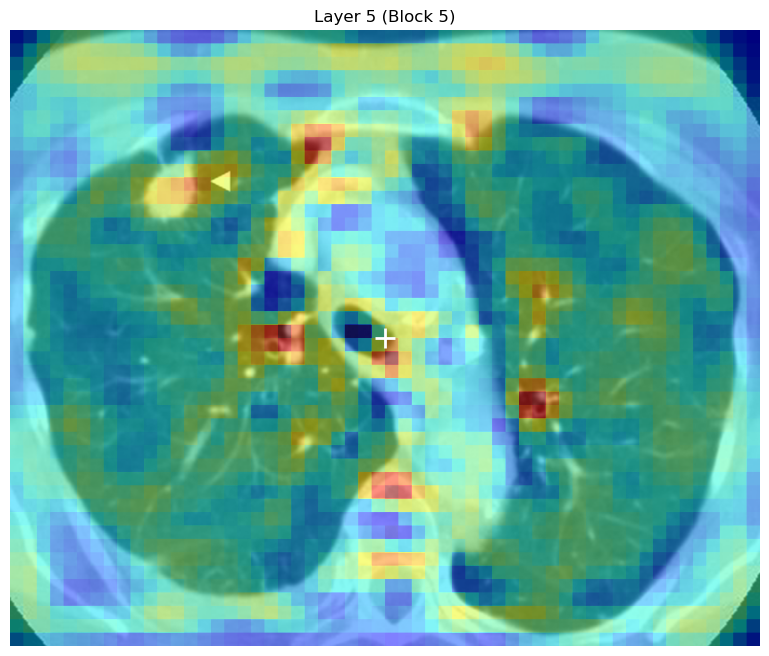

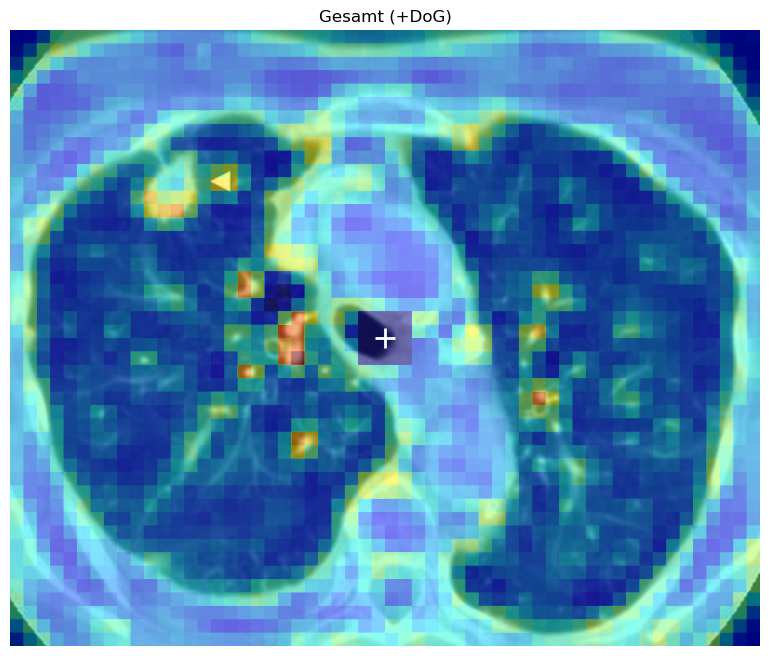

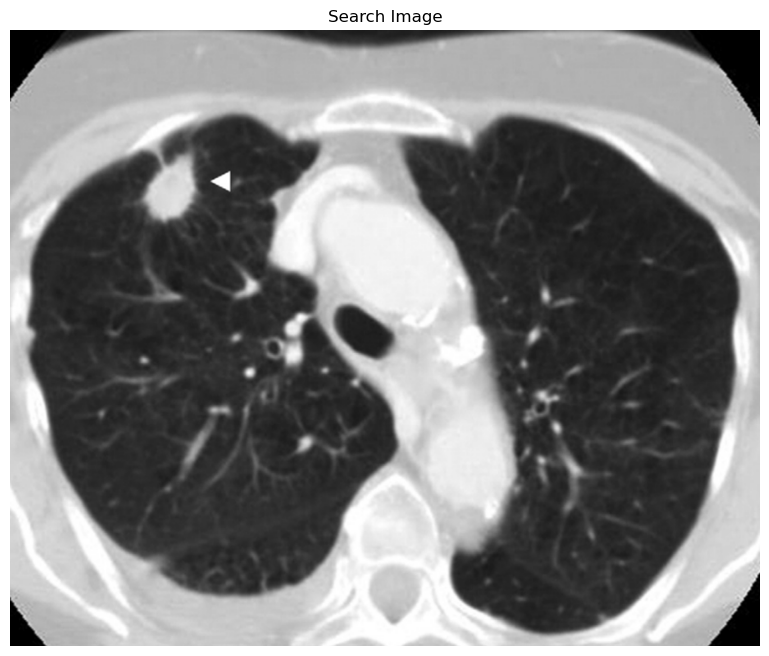

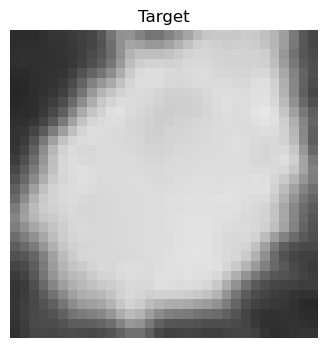

In [20]:
def window_to_stim(m, fix):
    """1600x1600-Fenstermap um Fixation fix (Stimulus-Koordinaten) -> HxW-Stimulusbereich."""
    r0, c0 = E - fix[0], E - fix[1]
    return m[r0:r0+H, c0:c0+W]

fix_idx = 0
fix = saccade[fix_idx]
maps = [window_to_stim(m, fix) for m in layer_maps[fix_idx]] + [window_to_stim(attn_maps[fix_idx], fix)]
titles = ["Layer 3 (Block 3)", "Layer 4 (Block 4)", "Layer 5 (Block 5)", "Gesamt (+DoG)"]
fnames = ["attention_layer3", "attention_layer4", "attention_layer5", "attention_overall"]

for m, t, f in zip(maps, titles, fnames):
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(search_img)
    ax.imshow(m, cmap='jet', alpha=0.5)
    ax.plot(fix[1], fix[0], 'w+', ms=15, mew=2)
    ax.set_title(t); ax.axis('off')
    fig.savefig(out_dir / f"{f}.png", dpi=150, bbox_inches='tight')
    plt.show()

target_img = cv2.cvtColor(cv2.imread(target_path), cv2.COLOR_BGR2RGB)
for img, t, f in [(search_img, "Search Image", "search_image"), (target_img, "Target", "target_image")]:
    fig, ax = plt.subplots(figsize=(10, 8) if f == "search_image" else (4, 4))
    ax.imshow(img); ax.set_title(t); ax.axis('off')
    fig.savefig(out_dir / f"{f}.png", dpi=150, bbox_inches='tight')
    plt.show()

## Scanpath

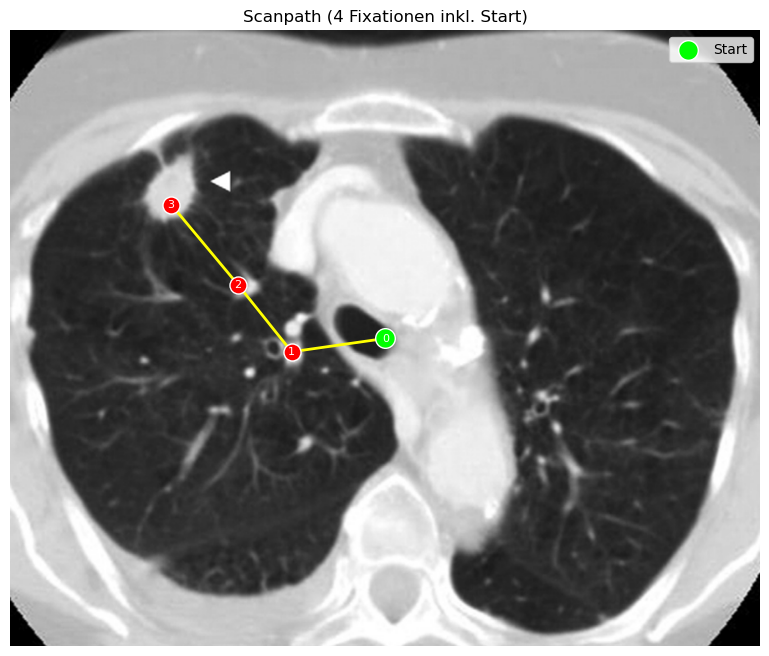

In [17]:
fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(search_img)
ax.plot(saccade[:, 1], saccade[:, 0], '-', color='yellow', lw=2)
ax.scatter(saccade[:, 1], saccade[:, 0], s=150, c='red', edgecolors='white', zorder=3)
ax.scatter(saccade[0, 1], saccade[0, 0], s=200, c='lime', edgecolors='white', zorder=4, label='Start')
for i, (r, c) in enumerate(saccade):
    ax.text(c, r, str(i), color='white', ha='center', va='center', fontsize=8, zorder=5)
ax.legend(loc='upper right'); ax.axis('off')
ax.set_title(f"Scanpath ({len(saccade)} Fixationen inkl. Start)")
fig.savefig(out_dir / "scanpath.png", dpi=150, bbox_inches='tight')
plt.show()

## Blur der Pooling-Layers

Alle Conv-Layers werden durch die Identität ersetzt, also weggelassen. Ein 3×3-Conv mit Identitätskern und ReLU auf nichtnegativen Pixeln ändert nichts. Das rohe RGB-Fenster der ersten Fixation (1600×1600, 0–255) läuft durch die 5 eccNET-Pooling-Layers. Pool 1/2 sind uniform (`ecc_slope=0`), Pool 3–5 exzentrizitätsabhängig. Die Ausgaben nach Pool 3/4/5 (200², 100², 50²) werden auf 1600² hochskaliert und auf den Stimulusbereich zugeschnitten.

2026-10-08 16:26:48.368335: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:114] Plugin optimizer for device_type GPU is enabled.


1/1 [==============================] - 1s 911ms/step
[(1, 200, 200, 3), (1, 100, 100, 3), (1, 50, 50, 3)]


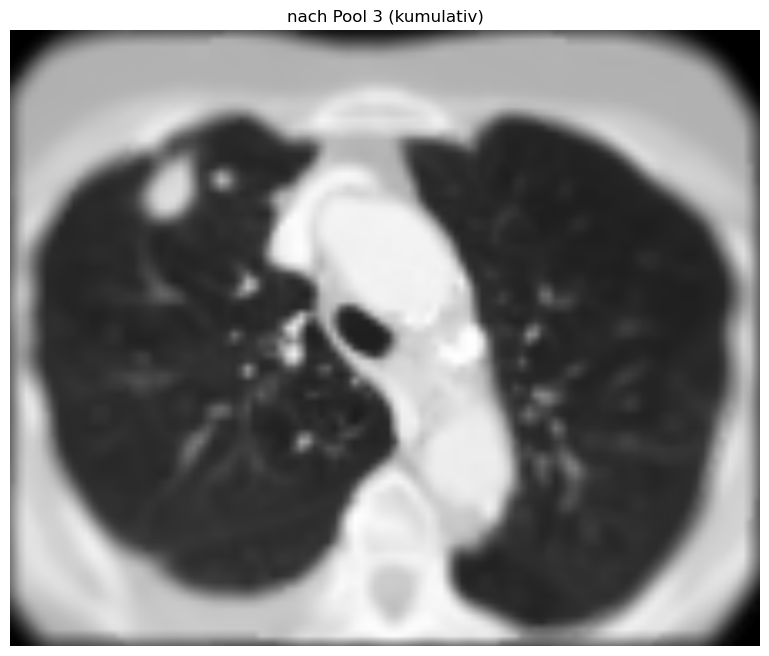

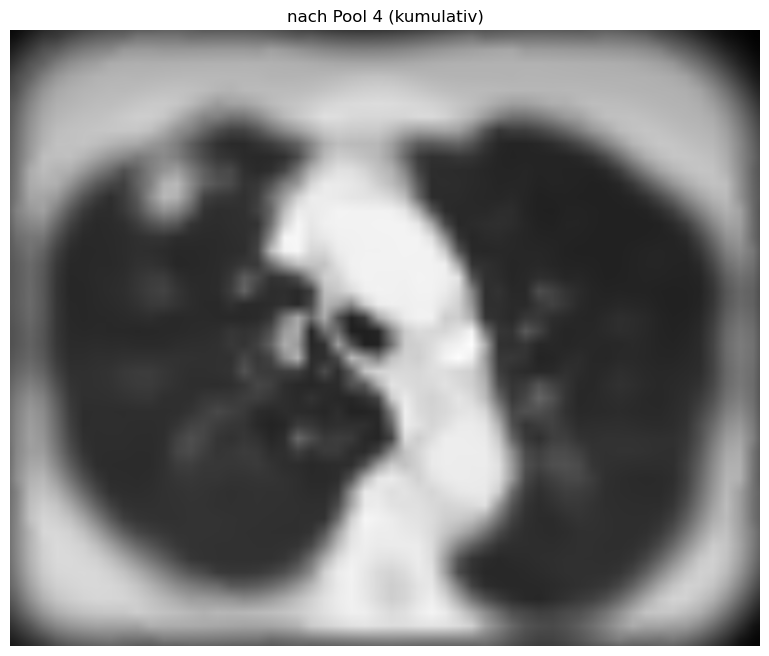

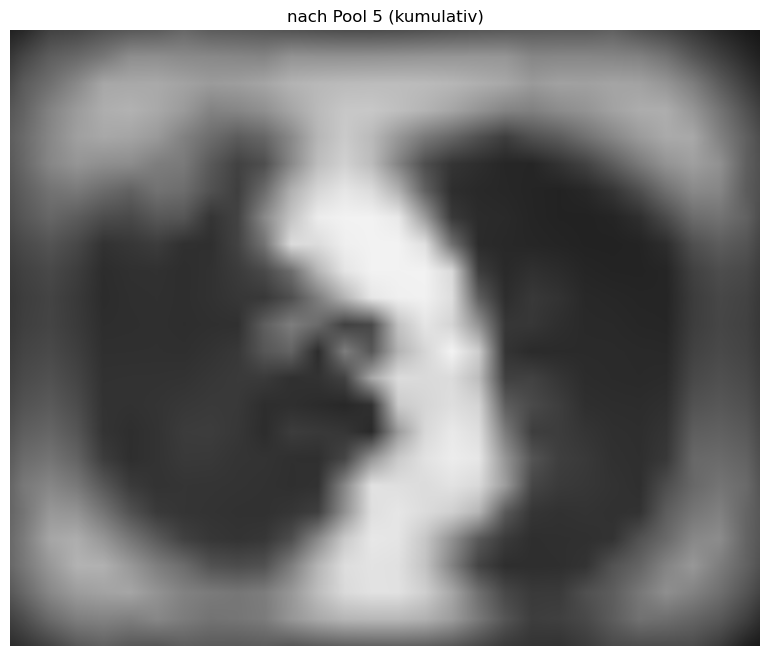

In [19]:
inp = tf.keras.layers.Input(shape=(2*E, 2*E, 3))
x = inp
pool_outs = []
for d in range(1, 6):
    x = pool_layer(x, eccParam=model_desc['eccParam'], layer=d, ecc_depth=model_desc['ecc_depth'], depth=d, name=f"Pool{d}")
    pool_outs.append(x)
pool_model = tf.keras.models.Model(inputs=inp, outputs=pool_outs[2:5])

window = vis_crops[0].astype(np.float32)[None]            # Fenster um die 1. Fixation
blur_outs = pool_model.predict(window)
print([o.shape for o in blur_outs])

blur_imgs = [window_to_stim(cv2.resize(o[0], (2*E, 2*E), interpolation=cv2.INTER_LINEAR), saccade[0]) for o in blur_outs]

for b, d in zip(blur_imgs, [3, 4, 5]):
    fig, ax = plt.subplots(figsize=(10, 8))
    ax.imshow(np.clip(b, 0, 255).astype(np.uint8))
    ax.set_title(f"nach Pool {d} (kumulativ)"); ax.axis('off')
    fig.savefig(out_dir / f"blur_pool{d}.png", dpi=150, bbox_inches='tight')
    plt.show()